# Initialization

Imports:

In [ ]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-
"""
Created on Sat Dec 30 20:02:22 2017

@author: Kamessi
"""
import matplotlib.pyplot as plt
import csv
import numpy as np
from scipy import linalg as LA
from sklearn.linear_model import LinearRegression
import statsmodels.api as sm
import math

print("Imports Complete")

def read_it(filename):
    f = open(filename,'r', encoding='cp1252')
    reader = csv.reader(f)
    raw_matrix = []
    for row in reader:
        temp = []
        for i in range(0,len(row)):
            try:
                temp.append(float(row[i]))
            except ValueError:
                #print(row[i])
                temp.append(row[i])
        raw_matrix.append(temp)
    f.close()
    return raw_matrix

/usr/local/lib/python3.7/dist-packages/statsmodels/tools/_testing.py:19: FutureWarning: pandas.util.testing is deprecated. Use the functions in the public API at pandas.testing instead.
  import pandas.util.testing as tm


Imports Complete


File Upload:
Remember to reup file when kernel is restarted

In [ ]:
from google.colab import drive
drive.mount('/content/drive/')
root_path = 'drive/My Drive/ECI Research/Spring 2020/Data/'


#Read the raw matrix
raw_matrix = read_it(root_path+"2013-2018 cleaned/2013clean.csv")
print("File Uploaded")

Mounted at /content/drive/
File Uploaded


# SOI Calculation

In [ ]:
#compute mcp
product_list = raw_matrix[0][1::]
country_list = []
for i in range(1,len(raw_matrix)):
    country_list.append(raw_matrix[i][0])

country_sum = []
for i in range(1,len(raw_matrix)):
    #print(raw_matrix[i][1::])
    country_sum.append(np.sum(raw_matrix[i][1::]))

product_sum = []
for i in range(1,len(raw_matrix[0])):
    product = 0
    for j in range(1,len(raw_matrix)):
        product += raw_matrix[j][i]
    product_sum.append(product)
total_sum = np.sum(product_sum)

mcp = []

for i in range (1,len(raw_matrix)):
    country_row = []
    for j in range(1,len(raw_matrix[i])):
        percentage = raw_matrix[i][j]/country_sum[i-1]
        total_percentage = product_sum[j-1]/total_sum
        if percentage > total_percentage:
            country_row.append(1)
        else:
            country_row.append(0)
    mcp.append(country_row)

#compute mpp
country_sum = []
for i in range(0,len(mcp)):
    country_sum.append(np.sum(mcp[i]))

product_sum = []
for i in range(0,len(mcp[0])):
    product = 0
    for j in range(0,len(mcp)):
        product += mcp[j][i]
    product_sum.append(product)
total_sum = np.sum(product_sum)

mpp = []
for i in range(0,len(mcp[0])):
    product_row = []
    for j in range(0,len(mcp[0])):
        temp_sum = 0
        for k in range(0,len(mcp)):
            try:
                temp_sum += (mcp[k][i] * mcp[k][j]/(country_sum[k]*product_sum[i]))
            except:
                pass
        product_row.append(temp_sum)
    mpp.append(product_row)


categorization verified
[[-28666788.64, 38770540.5, -134741933.8, 423829941.6, -91761283.31, -117100156.3, -207486355.2, 9754749.61, 254557782.9, -44985679.94, -303032514.6, -701858818.3, -484656628.8, 974726.55, -37652442.08, -28561116.64, -1371186754.0, -3376250000.0], [-3625957.77, 13925027.81, 111520826.2, 14325802693.0, 612459168.6, 273914600.2, -56222756.08, -1145022.22, 294375.21, -1214783.0, -237056301.1, -69186599.41, -317496287.3, -10096.16, -5489704.31, -21117130.21, 215765660.7, 1216552830.0], [-386497.57, 2159395.12, 5259718.74, 21394180006.0, -334261.1, -15847393.63, 6451391.59, -39266282.22, 222806.82, -118938.35, 31335315.8, -102126994.4, -651714618.4, -40957.94, -4928614.88, 368824121.9, -762800916.5, 2014433237.0], [856525242.0, 2209706038.0, 6747633373.0, -2192747866.0, 256306133.6, 911995661.0, 627911583.0, 80596322.5, -7083779.9, -33189383.7, -306713191.0, -191080267.0, 2654278137.0, -7978107.7, -96891145.7, 833534371.0, 3446725309.0, -7651353551.0], [6837514690.0,

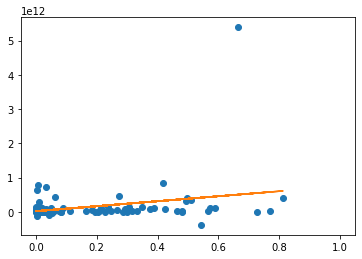

In [ ]:
#compute PCI
mpp = np.array(mpp)

e_vals, e_vecs = LA.eig(mpp)
eigenvectors = e_vecs.tolist()
eigen = []
for eigenvector in eigenvectors:
    temp = []
    for col in eigenvector:
        temp.append(col.real)
    eigen.append(temp)

vector = []
for i in range(0,len(eigen)):
    vector.append(eigen[i][1])

pci = []
if vector[len(vector)-2] > 0:
    for item in vector:
        pci.append((item-np.mean(vector))/np.std(vector))
else:
    for item in vector:
        pci.append((-item+np.mean(vector))/np.std(vector))

#compute proximity
proximity = []
for i in range(0,len(mcp[0])):
    product_row = []
    for j in range(0,len(mcp[0])):
        temp_sum = 0
        for k in range(0,len(mcp)):
            try:
                temp_sum += mcp[k][i] * mcp[k][j]
            except:
                pass
        p0 = product_sum[i]
        p1 = product_sum[j]
        if p0 < p1:
            large = p1
        else:
            large = p0
        product_row.append(temp_sum/large)
    proximity.append(product_row)

#compute actual distance
distance = []
for i in range(0,len(mcp)):
    product_row = []
    for j in range(0,len(mcp[0])):
        sum1 = 0
        for k in range(0,len(mcp[0])):
            try:
                sum1 += (1-mcp[i][k])*proximity[j][k]
            except:
                pass
        sum2 = 0
        for k in range(0,len(mcp[0])):
            try:
                sum2 += proximity[j][k]
            except:
                pass
        if mcp[i][j] == 1:
            product_row.append(0)
        else:
            product_row.append(sum1/sum2)
    distance.append(product_row)

#compute opportunity gain
opportunity_gain = []
for i in range(0,len(mcp)):
    country_row = []
    for j in range(0,len(mcp[0])):
        gain = 0
        for k in range(0,len(mcp[0])):
            temp = 0
            for l in range(0,len(mcp[0])):
                temp += proximity[l][k]
            gain += (proximity[j][k]/temp)*(1-mcp[i][k])*pci[k]
        gain = gain - (1-distance[i][j]) * pci[j]
        country_row.append(gain)
    opportunity_gain.append(country_row)


#compute ADI
raw_matrix = read_it(root_path+"ADI.csv")
raw_matrix = np.array(raw_matrix)
raw_matrix = np.transpose(raw_matrix)
product_list2 = raw_matrix[0][1::]
country_list2 = []
for i in range(1,len(raw_matrix)):
    country_list2.append(raw_matrix[i][0])

adi = []
for i in range(1,len(raw_matrix)):
    temp = []
    for j in range(1,len(raw_matrix[0])):
        temp.append(float(raw_matrix[i][j]))
    adi.append(temp)

#compute SOI
soi = []

if len(product_list) == len(product_list2):
    print("categorization verified")

print(adi)
common = []
for i in range(0,len(country_list)):
    if country_list[i] in country_list2:
        for j in range(0,len(country_list2)):
            if country_list[i] == country_list2[j]:
                dependent = adi[j]
                independent = []
                for item in opportunity_gain[i]:
                    independent.append([item])
                reg = LinearRegression()
                reg.fit(independent, dependent)
                r_2 = reg.score(independent, dependent)
                common.append(country_list[i])
                if country_list[i] == "China":
                    matrix = open("soi analysis Ajit.csv",'w',newline='')
                    writer = csv.writer(matrix)
                    start = ["Product","OG","Export Increase"]
                    writer.writerow(start)
                    for i in range(0,len(independent)):
                        temp = [product_list[i],independent[i][0],dependent[i]]
                        writer.writerow(temp)
                    matrix.close()
                soi.append(r_2)

print("Mean SOI: ",np.mean(soi))

matrix = open("structual optimality index Ajit.csv",'w',newline='')
writer = csv.writer(matrix)
col_name = ["Country","SOI"]
writer.writerow(col_name)
for i in range(0,len(soi)):
    temp = [common[i],soi[i]]
    writer.writerow(temp)
matrix.close()

#comprehensive regression
raw_matrix = read_it(root_path+"GDP.csv")
country_list3 = []
gdp_change = []
for i in range(1,len(raw_matrix)):
    country_list3.append(raw_matrix[i][0])
    gdp_change.append(float(raw_matrix[i][2])-float(raw_matrix[i][1]))

independent = []
dependent = []
name = []

for i in range(0,len(common)):
    if common[i] in country_list3:
        for j in range(0,len(country_list3)):
            if common[i] == country_list3[j]:
                name.append(country_list3[j])
                dependent.append(gdp_change[j])
                independent.append(soi[i])

data = np.array(independent)
X = sm.add_constant(data)
model = sm.OLS(dependent, X).fit()
print(model.summary())
plt.scatter(independent, dependent)

m, b = np.polyfit(independent, dependent, 1)
plt.plot(X, m*X + b)
print(m,b)
plt.show()